# 06 · Estrategia de validación

**Términos que se usan en este notebook:** [entrenamiento, validación y prueba](../docs/entrega_1/glosario.md) (ajustar el modelo / elegir entre candidatos / medirlo una sola vez al final), [brecha](../docs/entrega_1/glosario.md) (sesiones que se descartan entre dos conjuntos para que ninguna etiqueta mire dentro del conjunto siguiente), [fuga](../docs/entrega_1/glosario.md) (información del conjunto de evaluación que se cuela en el ajuste), [etiqueta censurada](../docs/entrega_1/glosario.md) (sin futuro suficiente para resolverse), [tasa de toque](../docs/entrega_1/glosario.md) (proporción de filas con `y = 1`), [decil](../docs/entrega_1/glosario.md) (cada uno de los 10 grupos de igual tamaño al ordenar de menor a mayor), [σ252](../docs/entrega_1/glosario.md) (volatilidad diaria del último año) y [bootstrap por bloques de fechas](../docs/entrega_1/glosario.md) (remuestreo de tramos consecutivos de fechas, conserva la dependencia en el tiempo).

**Objetivo.** Fijar y verificar cómo se separan los datos para entrenar, elegir y probar el modelo, sin que ninguna etiqueta mire al conjunto siguiente, y medir si cada conjunto se parece al total con tres criterios **fijados antes de medir**.

**Punto del enunciado que cubre.** Punto 9 (estrategia de validación). La partición, la brecha y las etiquetas son las de las funciones de `comunes.py`; este notebook solo las ejecuta y las audita.

**Qué alimenta.** El notebook 07 (modelos) usa esta partición tal cual; el 08 (simulación) usa la misma con calendario semanal. Las cifras quedan en `data/resultados/nb06.json`.

**Contenido.** §1 los datos · §2 la partición y la brecha · §3 fuga de selección declarada · §4 ausencia de fuga de etiquetas · §5 conservación de distribuciones · §6 si un conjunto no cumple · §7 la prueba por año · §8 resultados.

In [1]:
import json, sys, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sys.path.insert(0, "."); import comunes as cm      # nbconvert ejecuta el kernel en notebooks/, donde está comunes.py
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 30)

# Constantes del notebook. Fechas de la partición, BRECHA, REPS_BOOT, BLOQUE_FECHAS y los criterios viven en comunes.py (cm.<nombre>).
CONJUNTOS = ["entrenamiento", "validacion", "prueba"]
SUBPERIODOS = {"2010–2012": (2009, 2012), "2013–2019": (2013, 2019), "2020–2021": (2020, 2021), "2022+": (2022, 2100)}   # 04_enfoque_analitico.md §4.5
fm = lambda n: f"{n:,}".replace(",", " ")   # miles con espacio, como en el texto
res = {}                                           # cifras que se guardan en data/resultados/nb06.json
cm.DIR_ASSETS_E2.mkdir(parents=True, exist_ok=True)

## 1. Los datos

Es la misma tabla del notebook 05, reconstruida con las mismas funciones (no se pasa por archivos). La partición se asigna sobre la tabla **completa**, antes de filtrar, porque la brecha se cuenta sobre el calendario que recibe `asignar_conjunto`; la función no marca las filas censuradas (quedan como "prueba"), así que se separan con `censurada`.

In [2]:
precios = cm.cargar_snapshot("precios_diarios")
precios = precios[precios.ticker.isin(cm.tickers())].copy()
precios["fecha"] = precios["fecha"].astype("datetime64[ns]")
assert precios.ticker.nunique() == 21
calendario = pd.DatetimeIndex(np.sort(precios.fecha.unique()))         # calendario de sesiones de precios_diarios
pos = pd.Series(np.arange(len(calendario)), index=calendario)          # posición (número de sesión) de cada fecha

tabla = cm.tabla_modelo(cm.construir_panel_diario(precios))
tabla["conjunto"] = cm.asignar_conjunto(tabla["fecha"])                # sobre la tabla completa
cens = tabla[tabla.censurada]                                          # se reportan aparte
usables = tabla[(~tabla.censurada) & (tabla.conjunto != "brecha")]     # unión de los tres conjuntos: sin brecha ni censuradas
print(f"tabla completa: {fm(len(tabla))} filas · censuradas: {fm(len(cens))} · brecha: {fm(int((tabla.conjunto == 'brecha').sum()))} · utilizables: {fm(len(usables))}")
print(usables.groupby("conjunto").size().loc[CONJUNTOS].to_string())

tabla completa: 354 648 filas · censuradas: 5 040 · brecha: 10 080 · utilizables: 339 528
conjunto
entrenamiento    100632
validacion        79464
prueba           159432


## 2. La partición y la brecha

La partición fijada en la spec es **cronológica** (nunca aleatoria: mezclar fechas llevaría el futuro al entrenamiento):

| Conjunto | Años | Uso |
|---|---|---|
| Entrenamiento | 2009–2014 | ajustar el modelo |
| Validación | 2015–2018 | elegir entre candidatos; la métrica se reporta año por año |
| Prueba | 2019 en adelante | se usa una sola vez, al final |

**Brecha.** La etiqueta de una fila de t mira 60 sesiones hacia adelante. Una fila de las últimas 60 sesiones del entrenamiento tendría una etiqueta que depende de precios de validación. Para evitarlo se descartan las **60 últimas sesiones antes de cada frontera**. Al reentrenar el modelo final con 2009–2018 la brecha se aplica antes de la prueba (`final = True`).

In [3]:
filas = []
for c in CONJUNTOS:
    d = usables[usables.conjunto == c]
    filas.append({"conjunto": c, "primera_fecha": d.fecha.min().date(), "ultima_fecha": d.fecha.max().date(),
                  "sesiones": d.fecha.nunique(), "filas": len(d), "empresas": d.ticker.nunique()})
particion = pd.DataFrame(filas); print("Partición con las fechas reales (filas utilizables):"); print(particion.to_string(index=False))

br = tabla[tabla.conjunto == "brecha"]
fronteras = {"entrenamiento → validación": br[br.fecha < cm.INICIO_VALIDACION], "validación → prueba": br[br.fecha >= cm.INICIO_VALIDACION]}
filas_b = [{"frontera": n, "desde": b.fecha.min().date(), "hasta": b.fecha.max().date(), "sesiones": b.fecha.nunique(), "filas_descartadas": len(b)}
           for n, b in fronteras.items()]
print("\nBrecha (las 60 últimas sesiones antes de cada frontera):"); print(pd.DataFrame(filas_b).to_string(index=False))

# Fin de la prueba: última fecha con etiqueta resuelta; después vienen las censuradas
ultima_precio, ultima_etiqueta = calendario[-1], usables.fecha.max()
print(f"\nÚltima fecha de precios_diarios: {ultima_precio.date()} · última fecha con etiqueta resuelta (fin de la prueba): {ultima_etiqueta.date()}")
print(f"→ {int((calendario > ultima_etiqueta).sum())} sesiones sin etiqueta resuelta ({cens.fecha.min().date()} a {cens.fecha.max().date()}): censuradas, fuera de todo conjunto")

# Variante del modelo final (2009–2018 juntos): entrenamiento_final y la misma brecha antes de la prueba
fin = cm.asignar_conjunto(tabla["fecha"], final=True)
fin_ok = tabla.assign(c=fin)[~tabla.censurada]
print("\nmodelo final (final=True), filas utilizables:", fin_ok.groupby("c").size().to_dict())
d_ef = fin_ok[fin_ok.c == "entrenamiento_final"]
print(f"entrenamiento_final: {d_ef.fecha.min().date()} a {d_ef.fecha.max().date()}")
res["particion"] = {r["conjunto"]: {k: (str(v) if not isinstance(v, (int, np.integer)) else int(v)) for k, v in r.items() if k != "conjunto"} for r in filas}
res["brecha"] = {r["frontera"]: {k: (str(v) if not isinstance(v, (int, np.integer)) else int(v)) for k, v in r.items() if k != "frontera"} for r in filas_b}
res["fin_prueba"] = {"ultima_fecha_precios": str(ultima_precio.date()), "ultima_fecha_etiqueta_resuelta": str(ultima_etiqueta.date()),
                     "sesiones_censuradas": int((calendario > ultima_etiqueta).sum())}

Partición con las fechas reales (filas utilizables):
     conjunto primera_fecha ultima_fecha  sesiones  filas  empresas
entrenamiento    2010-01-04   2014-10-06      1198 100632        21
   validacion    2015-01-02   2018-10-03       946  79464        21
       prueba    2019-01-02   2026-07-22      1898 159432        21

Brecha (las 60 últimas sesiones antes de cada frontera):
                  frontera      desde      hasta  sesiones  filas_descartadas
entrenamiento → validación 2014-10-07 2014-12-31        60               5040
       validación → prueba 2018-10-04 2018-12-31        60               5040

Última fecha de precios_diarios: 2026-10-15 · última fecha con etiqueta resuelta (fin de la prueba): 2026-07-22
→ 60 sesiones sin etiqueta resuelta (2026-07-23 a 2026-10-15): censuradas, fuera de todo conjunto

modelo final (final=True), filas utilizables: {'brecha': 5040, 'entrenamiento_final': 185136, 'prueba': 159432}
entrenamiento_final: 2010-01-04 a 2018-10-03


**Lectura.** Las fechas reales son: entrenamiento del 2010-01-04 al 2014-10-06 (1 198 sesiones, 100 632 filas; la historia con σ252 empieza en 2010-01-04 porque las 252 primeras sesiones son calentamiento), validación del 2015-01-02 al 2018-10-03 (946 sesiones, 79 464 filas) y prueba del 2019-01-02 al 2026-07-22 (1 898 sesiones, 159 432 filas). Las dos brechas son de 60 sesiones (2014-10-07 a 2014-12-31 y 2018-10-04 a 2018-12-31) y descartan 5 040 filas cada una (60 × 21 empresas × 4 k). La prueba termina el 2026-07-22, la última fecha con etiqueta resuelta; las 60 sesiones posteriores (2026-07-23 a 2026-10-15) son las censuradas y quedan fuera. El modelo final (2009–2018) tendrá 185 136 filas, hasta el 2018-10-03, con la misma brecha antes de la prueba.

## 3. Fuga de selección, declarada

Hay una fuga que la brecha no puede evitar y se **declara** en lugar de esconderla: **N = 60 se eligió solo con datos hasta 2018** (nb04 §4.3), pero el tramo **2019 en adelante ya se miró en la entrega 1** para una pregunta distinta: descartar 7 indicadores técnicos (nb04 §5), lo que dejó solo las variables de magnitud que usa este modelo. Por eso la prueba 2019+ **no es virgen** para esa decisión: sus resultados se leen como **confirmación, no como descubrimiento**. 

**Mitigación.** (1) Declararla (aquí y en el reporte); (2) reportar la prueba **también por año** (§7 muestra la tasa por año y el notebook 07 las métricas por año), para que un buen resultado sostenido en un solo año no se confunda con una señal estable; (3) no reabrir la partición ni los criterios después de ver la prueba.

## 4. Ausencia de fuga de etiquetas (celda ejecutada)

Para cada frontera se toma la **última fecha con etiqueta** de cada conjunto (la anterior a la brecha) y se calcula en qué sesión termina su ventana de 60 sesiones (`fecha + 60 sesiones` del calendario de `precios_diarios`). Esa sesión debe caer **antes** del inicio del conjunto siguiente. Se revisan además **todas** las filas del conjunto, no solo la última. Como control negativo (para mostrar que la prueba puede fallar) se repite la misma cuenta sin brecha, con todas las filas anteriores a la frontera.

In [4]:
def inicio_real(fecha_corte):                       # primera sesión del calendario en o después de la frontera
    return calendario[calendario >= pd.Timestamp(fecha_corte)][0]

def violaciones(df, inicio_siguiente):              # filas cuya ventana de 60 sesiones termina en o después del siguiente conjunto
    fin_ventana = calendario[(pos.loc[df.fecha].to_numpy() + cm.N_DIAS)]
    return int((fin_ventana >= inicio_siguiente).sum())

casos = [("entrenamiento → validación", "entrenamiento", cm.INICIO_VALIDACION, usables, "conjunto"),
         ("validación → prueba", "validacion", cm.INICIO_PRUEBA, usables, "conjunto")]
filas, total_viol = [], 0
for nombre, conj, corte, df, col in casos:
    d = df[df[col] == conj]; sig = inicio_real(corte)
    ult = d.fecha.max(); fin_v = calendario[pos[ult] + cm.N_DIAS]
    v = violaciones(d, sig); total_viol += v
    # control negativo: todas las filas no censuradas anteriores a la frontera, brecha incluida
    previas = tabla[(~tabla.censurada) & (tabla.fecha < sig) & (tabla.fecha >= (cm.INICIO_VALIDACION if conj == "validacion" else "2000-01-01")) ]
    filas.append({"frontera": nombre, "ultima_fecha_con_etiqueta": ult.date(), "fin_de_su_ventana": fin_v.date(),
                  "inicio_siguiente": sig.date(), "sesiones_de_margen": int(pos[sig] - pos[fin_v]), "filas_con_fuga": v,
                  "control_sin_brecha": violaciones(previas, sig)})
# Modelo final: 2009–2018 sin validación, brecha antes de la prueba
d = fin_ok[fin_ok.c == "entrenamiento_final"]; sig = inicio_real(cm.INICIO_PRUEBA); ult = d.fecha.max()
v = violaciones(d, sig); total_viol += v
filas.append({"frontera": "entrenamiento_final → prueba", "ultima_fecha_con_etiqueta": ult.date(), "fin_de_su_ventana": calendario[pos[ult] + cm.N_DIAS].date(),
              "inicio_siguiente": sig.date(), "sesiones_de_margen": int(pos[sig] - pos[calendario[pos[ult] + cm.N_DIAS]]), "filas_con_fuga": v,
              "control_sin_brecha": violaciones(tabla[(~tabla.censurada) & (tabla.fecha < sig)], sig)})
print(pd.DataFrame(filas).to_string(index=False))
fuga_etiquetas = total_viol
print(f"\nfuga_etiquetas: {fuga_etiquetas} filas")
assert fuga_etiquetas == 0 and all(f["control_sin_brecha"] > 0 for f in filas)
res["fuga_etiquetas"] = int(fuga_etiquetas)
res["fuga_etiquetas_detalle"] = [{k: (str(v) if hasattr(v, "year") else int(v) if isinstance(v, (int, np.integer)) else v) for k, v in f.items()} for f in filas]

                    frontera ultima_fecha_con_etiqueta fin_de_su_ventana inicio_siguiente  sesiones_de_margen  filas_con_fuga  control_sin_brecha
  entrenamiento → validación                2014-10-06        2014-12-31       2015-01-02                   1               0                5040
         validación → prueba                2018-10-03        2018-12-31       2019-01-02                   1               0                5040
entrenamiento_final → prueba                2018-10-03        2018-12-31       2019-01-02                   1               0                5040

fuga_etiquetas: 0 filas


**Lectura.** En las tres fronteras la ventana de 60 sesiones de la última fecha con etiqueta termina el 2014-12-31 o el 2018-12-31, una sesión antes del inicio del conjunto siguiente (2015-01-02 y 2019-01-02): 0 filas con fuga, `fuga_etiquetas = 0`, revisadas todas las filas de cada conjunto y no solo la última. La prueba puede fallar: sin la brecha, la misma cuenta daría 5 040 filas con fuga en cada frontera (60 sesiones × 21 empresas × 4 k). La brecha es, por tanto, justo lo que hace falta y no más: el margen es de una sola sesión.

## 5. Conservación de distribuciones

Un conjunto de evaluación solo dice algo útil si se parece al total en lo que el modelo mira. Se comparan los tres conjuntos con el **total** (la unión de los tres, sin brecha ni censuradas) con **tres criterios fijados antes de medir** (`cm.CRITERIOS_CONSERVACION`, de la spec):

1. **Tasa de toque:** |tasa del conjunto − tasa del total| ≤ 3 pp, **en cada uno de los 4 valores de k** (cumple si todos lo logran).
2. **Mediana de σ252:** |mediana del conjunto / mediana del total − 1| ≤ 20 %.
3. **Pesos por decil de σ252:** los deciles se calculan en el **total** (solo describen); el peso de cada decil en el conjunto debe estar a ≤ 5 pp del peso en el total (10 %).

No se cambian los criterios ni la partición después de medir: si un conjunto no cumple, se reporta cuánto se aparta y se explica (§6). El tamaño de la muestra no decide: la decisión es de **magnitud** (¿se parece lo suficiente?), y los IC del final son solo ayuda de lectura.

In [5]:
CRIT = cm.CRITERIOS_CONSERVACION
assert CRIT == {"tasa_pp": 0.03, "mediana_sigma_rel": 0.20, "decil_pp": 0.05}, "los criterios son los fijados en la spec"
print("criterios (sin retocar):", CRIT)
total = usables                                    # unión de los tres conjuntos

# Criterio 1: tasa de toque por conjunto y por k frente al total
tasa_tot = total.groupby("k").y.mean()
tasa_c = {c: usables[usables.conjunto == c].groupby("k").y.mean() for c in CONJUNTOS}
dif_tasa = pd.DataFrame({c: tasa_c[c] - tasa_tot for c in CONJUNTOS})
print("\ntasa de toque del total por k:", {str(float(k)): round(v, 4) for k, v in tasa_tot.items()})
print("\ndiferencia de tasa (conjunto − total), en pp:"); print((dif_tasa * 100).T.to_string())

# Criterio 2: mediana de σ252 (todas las filas; σ252 no depende de k)
med_tot = float(total.sigma252.median())
med = {c: float(usables[usables.conjunto == c].sigma252.median()) for c in CONJUNTOS}
rel = {c: med[c] / med_tot - 1 for c in CONJUNTOS}
print(f"\nmediana de σ252: total {med_tot:.5f}"); print(pd.DataFrame({"mediana": med, "relativa_al_total": rel}).loc[CONJUNTOS].to_string())

# Criterio 3: peso de cada decil de σ252 (deciles del total)
_, cortes = pd.qcut(total.sigma252, cm.DECILES_SIGMA, retbins=True)
def decil(s): return np.clip(np.digitize(s, cortes[1:-1], right=True), 0, cm.DECILES_SIGMA - 1)
pesos_tot = np.bincount(decil(total.sigma252), minlength=cm.DECILES_SIGMA) / len(total)
pesos = {c: np.bincount(decil(usables[usables.conjunto == c].sigma252), minlength=cm.DECILES_SIGMA) / (usables.conjunto == c).sum() for c in CONJUNTOS}
tab_dec = pd.DataFrame({"corte_sup_σ252": cortes[1:], "total": pesos_tot, **pesos}, index=[f"D{i+1}" for i in range(cm.DECILES_SIGMA)])
print("\npeso de cada decil de σ252 (deciles del total):"); print(tab_dec.to_string())
dif_dec = {c: (pesos[c] - pesos_tot) for c in CONJUNTOS}
print("\nmayor diferencia de peso por conjunto (pp):", {c: f"{np.abs(d).max()*100:.2f} en D{np.abs(d).argmax()+1}" for c, d in dif_dec.items()})

criterios (sin retocar): {'tasa_pp': 0.03, 'mediana_sigma_rel': 0.2, 'decil_pp': 0.05}

tasa de toque del total por k: {'0.5': 0.4408, '1.0': 0.1905, '1.5': 0.077, '2.0': 0.0333}

diferencia de tasa (conjunto − total), en pp:
k              0.5000  1.0000  1.5000  2.0000
entrenamiento -5.4912 -5.0194 -3.7229 -2.5133
validacion     3.5437  3.3102  1.5794  0.2609
prueba         1.6997  1.5183  1.5626  1.4563

mediana de σ252: total 0.01199
               mediana  relativa_al_total
entrenamiento   0.0104            -0.1360
validacion      0.0109            -0.0905
prueba          0.0138             0.1536

peso de cada decil de σ252 (deciles del total):
     corte_sup_σ252  total  entrenamiento  validacion  prueba
D1           0.0090 0.1000         0.2014      0.1383  0.0169
D2           0.0098 0.1000         0.1561      0.1476  0.0409
D3           0.0104 0.1000         0.1566      0.1216  0.0535
D4           0.0112 0.1000         0.0980      0.1472  0.0777
D5           0.0120 0.1000     

In [6]:
# Veredicto de cada criterio (con los valores de cm.CRITERIOS_CONSERVACION, sin retocar)
cons = {}
for c in CONJUNTOS:
    max_t = float(dif_tasa[c].abs().max()); max_d = float(np.abs(dif_dec[c]).max())
    cons[c] = {
        "tasa": {"valor": {str(float(k)): float(v) for k, v in tasa_c[c].items()}, "total": {str(float(k)): float(v) for k, v in tasa_tot.items()},
                 "diferencias_pp": {str(float(k)): float(v * 100) for k, v in dif_tasa[c].items()}, "max_dif_pp": max_t * 100,
                 "umbral_pp": CRIT["tasa_pp"] * 100, "cumple": bool(max_t <= CRIT["tasa_pp"])},
        "mediana_sigma": {"valor": med[c], "total": med_tot, "relativa": float(rel[c]), "umbral": CRIT["mediana_sigma_rel"],
                          "cumple": bool(abs(rel[c]) <= CRIT["mediana_sigma_rel"])},
        "pesos_decil": {"pesos": [float(x) for x in pesos[c]], "total": [float(x) for x in pesos_tot], "diferencias_pp": [float(x * 100) for x in dif_dec[c]],
                        "max_dif_pp": max_d * 100, "umbral_pp": CRIT["decil_pp"] * 100, "cumple": bool(max_d <= CRIT["decil_pp"])}}
resumen = pd.DataFrame({c: {"tasa: mayor |dif| (pp)": cons[c]["tasa"]["max_dif_pp"], "tasa cumple": cons[c]["tasa"]["cumple"],
                            "mediana σ252 rel.": cons[c]["mediana_sigma"]["relativa"], "mediana cumple": cons[c]["mediana_sigma"]["cumple"],
                            "decil: mayor |dif| (pp)": cons[c]["pesos_decil"]["max_dif_pp"], "decil cumple": cons[c]["pesos_decil"]["cumple"]} for c in CONJUNTOS})
print(resumen.to_string())
res["conservacion"] = cons
res["criterios_conservacion"] = CRIT

                        entrenamiento validacion prueba
tasa: mayor |dif| (pp)         5.4912     3.5437 1.6997
tasa cumple                     False      False   True
mediana σ252 rel.             -0.1360    -0.0905 0.1536
mediana cumple                   True       True   True
decil: mayor |dif| (pp)       10.1398     7.8957 8.3074
decil cumple                    False      False  False


**Lectura.** *Tasa de toque:* la prueba cumple (mayor diferencia 1,70 pp), el entrenamiento no (−5,49, −5,02 y −3,72 pp con k = 0,5, 1 y 1,5; solo k = 2 cumple, con −2,51) y la validación tampoco (+3,54 y +3,31 pp con k = 0,5 y 1; cumple con k = 1,5 y 2). *Mediana de σ252:* los tres cumplen (−13,6 %, −9,1 % y +15,4 %), aunque la prueba queda cerca del límite de 20 %. *Deciles:* los tres incumplen (mayor diferencia de 10,14 pp en D1 para entrenamiento, 7,90 pp en D10 para validación y 8,31 pp en D1 para prueba). Resultado: 5 de los 9 veredictos son `cumple = False`; se reportan y se explican en §6, sin cambiar criterios ni partición. Una advertencia sobre el criterio de tasa: con k = 2 el entrenamiento tiene una tasa de 0,8 % frente a 3,3 % del total (la cuarta parte) y aun así "cumple", porque la diferencia absoluta es de 2,5 pp; el criterio absoluto es poco exigente con eventos raros.

In [7]:
# Tablas descriptivas por conjunto (σ252, σ20/σ252 y |r| no dependen de k: se usan las filas con k = 1)
v1 = usables[usables.k == 1.0]
desc = v1.groupby("conjunto")[["sigma252", "sigma20_sigma252", "abs_r"]].agg(["mean", "median", "std", "min", "max"]).loc[CONJUNTOS]
print(desc.T.to_string())

conjunto                 entrenamiento  validacion  prueba
sigma252         mean           0.0115      0.0115  0.0149
                 median         0.0104      0.0109  0.0138
                 std            0.0036      0.0029  0.0046
                 min            0.0061      0.0056  0.0076
                 max            0.0334      0.0245  0.0446
sigma20_sigma252 mean           0.9246      0.9839  0.9487
                 median         0.8750      0.9332  0.8768
                 std            0.3150      0.3486  0.3860
                 min            0.2927      0.2584  0.2357
                 max            2.5941      2.6630  3.4064
abs_r            mean           0.0079      0.0084  0.0105
                 median         0.0058      0.0060  0.0075
                 std            0.0084      0.0090  0.0117
                 min            0.0000      0.0000  0.0000
                 max            0.3165      0.2094  0.2770


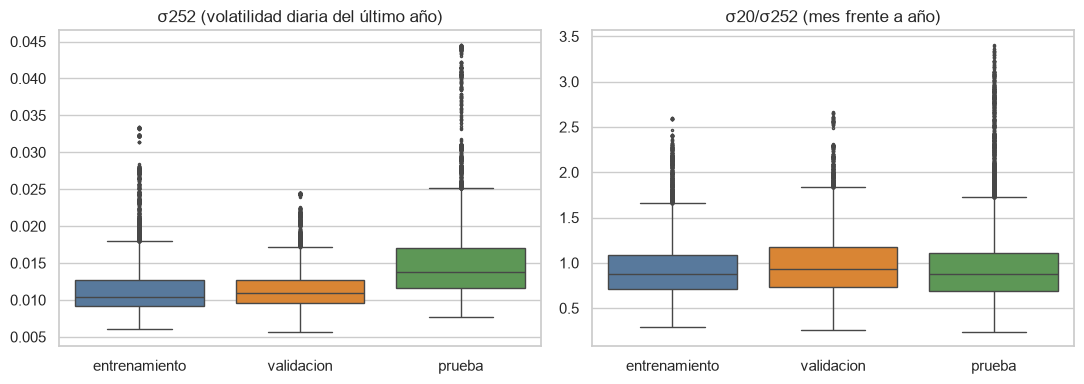

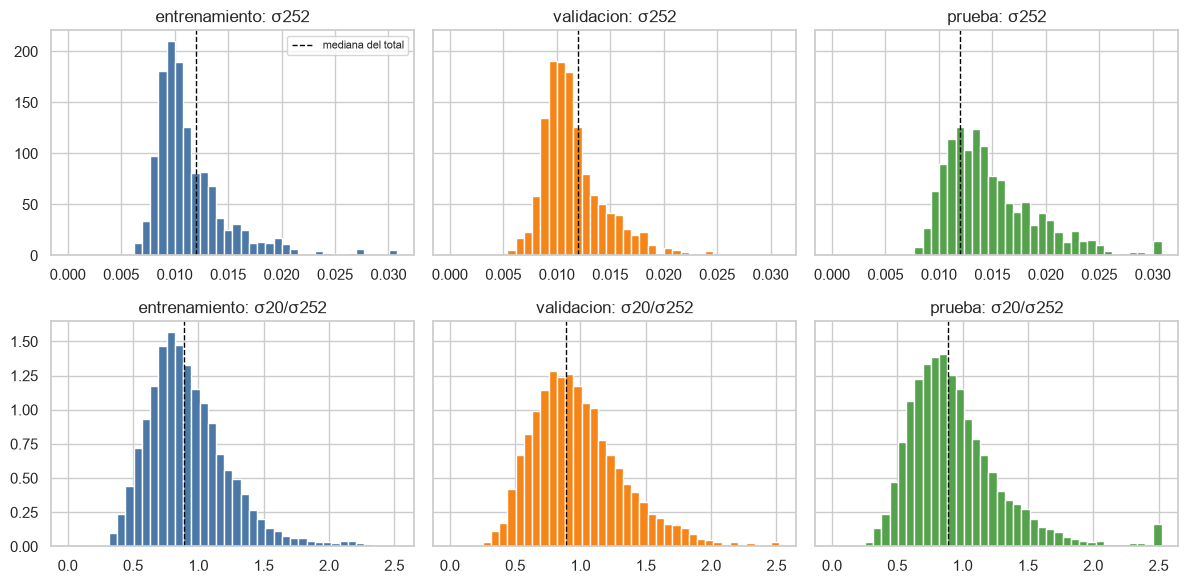

medianas σ252 (entrenamiento, validación, prueba): [0.0104, 0.0109, 0.0138] · σ20/σ252: [0.875, 0.933, 0.877]


In [8]:
# Figuras: boxplots e histogramas de σ252 y σ20/σ252 por conjunto
COL = {"entrenamiento": "#4c78a8", "validacion": "#f58518", "prueba": "#54a24b"}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, v, tit in zip(ax, ["sigma252", "sigma20_sigma252"], ["σ252 (volatilidad diaria del último año)", "σ20/σ252 (mes frente a año)"]):
    sns.boxplot(data=v1, x="conjunto", y=v, order=CONJUNTOS, palette=COL, hue="conjunto", legend=False, ax=a, fliersize=1.5)
    a.set_title(tit); a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS_E2 / "nb06_boxplots.png", dpi=130); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(12, 6), sharex="row", sharey="row")
for j, c in enumerate(CONJUNTOS):
    for i, (v, tit) in enumerate([("sigma252", "σ252"), ("sigma20_sigma252", "σ20/σ252")]):
        lim = (0, v1[v].quantile(0.995))
        ax[i, j].hist(v1.loc[v1.conjunto == c, v].clip(*lim), bins=40, range=lim, color=COL[c], edgecolor="white", density=True)
        ax[i, j].axvline(v1[v].median(), color="black", ls="--", lw=1, label="mediana del total")
        ax[i, j].set_title(f"{c}: {tit}")
        if i == 0 and j == 0: ax[i, j].legend(fontsize=8)
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS_E2 / "nb06_histogramas.png", dpi=130); plt.show()
print("medianas σ252 (entrenamiento, validación, prueba):", [round(float(v1[v1.conjunto == c].sigma252.median()), 4) for c in CONJUNTOS],
      "· σ20/σ252:", [round(float(v1[v1.conjunto == c].sigma20_sigma252.median()), 3) for c in CONJUNTOS])

**Lectura.** (En los histogramas la última barra agrupa la cola por encima del percentil 99,5.) La σ252 tiene mediana de 0,0104 en entrenamiento, 0,0109 en validación y 0,0138 en prueba (media 0,0115, 0,0115 y 0,0149); el máximo de la prueba (0,0446) es casi el doble del de validación (0,0245) y 1,3 veces el del entrenamiento (0,0334). En los boxplots la caja de la prueba queda desplazada hacia arriba y con cola larga (los episodios de 2020 y 2022), mientras entrenamiento y validación se parecen entre sí. El cociente σ20/σ252 es más estable: medianas de 0,875, 0,933 y 0,877, con la misma forma en los tres histogramas aunque la prueba llega a 3,41 frente a 2,59–2,66. El movimiento diario medio |r| sube de 0,0079 y 0,0084 a 0,0105 en la prueba. Lo que cambia entre conjuntos es el **nivel** de volatilidad, no la forma de la relación entre el mes y el año.

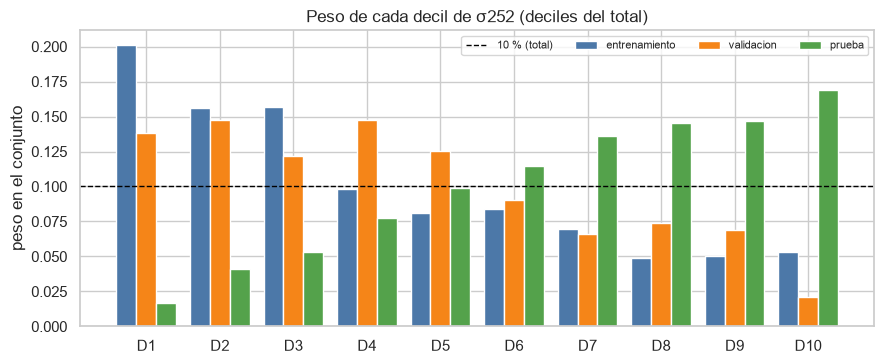

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(cm.DECILES_SIGMA); w = 0.27
for i, c in enumerate(CONJUNTOS):
    ax.bar(x + (i - 1) * w, pesos[c], w, color=COL[c], label=c)
ax.axhline(0.1, color="black", ls="--", lw=1, label="10 % (total)")
ax.set_xticks(x); ax.set_xticklabels([f"D{i+1}" for i in x]); ax.set_ylabel("peso en el conjunto")
ax.set_title("Peso de cada decil de σ252 (deciles del total)"); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS_E2 / "nb06_deciles.png", dpi=130); plt.show()

**Lectura.** El entrenamiento está cargado de días tranquilos: 20,1 % de sus filas caen en el primer decil de σ252 (σ252 ≤ 0,0090) y 15,6 % en el segundo, frente al 10 % esperado, y solo 5,3 % en el décimo. La prueba hace lo contrario: 1,7 % en D1 y 16,9 % en D10. La validación queda en medio, con 13,8–14,8 % en D1, D2 y D4 y solo 2,1 % en D10. Un conjunto que es un bloque de años no puede repartir sus filas como el total porque la volatilidad cambia por regímenes y la σ252 de una empresa se comparte entre días vecinos.

### 5.1 IC95 de la diferencia de tasa (solo ayuda de lectura)

Para cada conjunto y cada k se calcula el IC95 por **bootstrap por bloques de fechas** (`cm.ic_bootstrap_fechas`, bloques de `BLOQUE_FECHAS` = 60 sesiones, `REPS_BOOT` = 1000 réplicas) de la diferencia "tasa del conjunto − tasa del total". Sirve para ver cuánta de la diferencia es ruido de muestreo; **no decide** el cumplimiento (el criterio es de magnitud). El bloque de 60 sesiones respeta que filas de fechas vecinas, y de todas las empresas en un mismo día, no son independientes.

In [10]:
filas = []
for k in cm.K_GRID:
    dk = usables[usables.k == k][["fecha", "y", "conjunto"]].reset_index(drop=True)
    for c in CONJUNTOS:
        est, lo, hi = cm.ic_bootstrap_fechas(dk, lambda d, c=c: d.loc[d.conjunto == c, "y"].mean() - d["y"].mean(),
                                             bloque=cm.BLOQUE_FECHAS, reps=cm.REPS_BOOT, semilla=cm.SEMILLA)
        filas.append({"conjunto": c, "k": k, "dif_pp": est * 100, "ic_lo_pp": lo * 100, "ic_hi_pp": hi * 100, "cumple_3pp": abs(est) <= CRIT["tasa_pp"]})
ic = pd.DataFrame(filas); print(ic.to_string(index=False))
n_ic0 = int(((ic.ic_lo_pp <= 0) & (ic.ic_hi_pp >= 0)).sum())
print(f"\nIC95 que incluyen el 0: {n_ic0} de {len(ic)} diferencias de tasa")
res["ic_incluyen_cero"] = n_ic0
res["ic_dif_tasa_pp"] = [{**r, "k": float(r["k"]), "cumple_3pp": bool(r["cumple_3pp"])} for r in ic.to_dict("records")]

     conjunto      k  dif_pp  ic_lo_pp  ic_hi_pp  cumple_3pp
entrenamiento 0.5000 -5.4912  -11.1770    1.5639       False
   validacion 0.5000  3.5437   -3.3218   10.6012       False
       prueba 0.5000  1.6997   -3.0987    5.8106        True
entrenamiento 1.0000 -5.0194   -9.6006    0.3831       False
   validacion 1.0000  3.3102   -2.6353    9.9326       False
       prueba 1.0000  1.5183   -2.3762    5.0376        True
entrenamiento 1.5000 -3.7229   -6.5311   -0.9853       False
   validacion 1.5000  1.5794   -2.2923    5.9297        True
       prueba 1.5000  1.5626   -0.9611    4.4614        True
entrenamiento 2.0000 -2.5133   -4.4404   -0.9609        True
   validacion 2.0000  0.2609   -2.2823    2.9583        True
       prueba 2.0000  1.4563   -0.1245    3.7468        True

IC95 que incluyen el 0: 10 de 12 diferencias de tasa


**Lectura.** Los IC95 por bloques de fechas son anchos, de 3,5 a 13,9 pp (por ejemplo, el entrenamiento con k = 0,5: −5,49 pp, IC [−11,18; 1,56]). Solo con k = 1,5 y 2 el IC del entrenamiento excluye el 0 (−3,72 [−6,53; −0,99] y −2,51 [−4,44; −0,96]). Hay pocos bloques de 60 sesiones realmente distintos (unos 20 en entrenamiento y unos 16 en validación), por lo que parte de la diferencia con k = 0,5 y 1 podría ser ruido de muestreo. Esto no cambia el veredicto, que es de magnitud (±3 pp): el IC solo ayuda a leer cuánta de la diferencia es ruido.

## 6. Si un conjunto no cumple: cuánto se aparta y por qué

Para cada criterio con `cumple = False` se reporta cuánto se aparta y se explica con los **subperíodos** de la entrega 1 (2010–2012 salida de la crisis de 2008; la entrega 1 lo llama 2009–2012, pero el calentamiento de σ252 deja el primer dato en 2010-01-04; 2013–2019 expansión; 2020–2021 COVID; 2022+ mercado bajista de 2022). Es una explicación, no una corrección: ni los criterios ni la partición cambian. La tasa de toque por año calendario y k es `tasa_por_anio`.

In [11]:
anio = usables.assign(anio=usables.fecha.dt.year)
tasa_anio = anio.groupby(["anio", "k"]).y.agg(["mean", "size"]).unstack("k")
print("tasa de toque por año calendario × k:"); print(tasa_anio["mean"].to_string())
print("\nfilas por año (por k):"); print(tasa_anio["size"].iloc[:, 0].to_string())
def subp(a):
    for n, (i, f) in SUBPERIODOS.items():
        if i <= a <= f: return n
anio["subperiodo"] = anio.anio.map(subp)
tab_sp = anio.groupby(["subperiodo", "k"]).y.mean().unstack("k").loc[list(SUBPERIODOS)]
print("\ntasa de toque por subperíodo × k:"); print(tab_sp.to_string())
# Qué subperíodos componen cada conjunto (peso de cada subperíodo en el conjunto) y σ252 mediana por subperíodo
comp = pd.crosstab(anio.conjunto, anio.subperiodo, normalize="index").loc[CONJUNTOS, list(SUBPERIODOS)]
print("\npeso de cada subperíodo dentro de cada conjunto:"); print(comp.to_string())
print("\nσ252 mediana por subperíodo:", {n: round(float(anio[anio.subperiodo == n].sigma252.median()), 4) for n in SUBPERIODOS})
no_cumplen = [(c, crit) for c in CONJUNTOS for crit in ("tasa", "mediana_sigma", "pesos_decil") if not cons[c][crit]["cumple"]]
print("\ncriterios con cumple = False:", no_cumplen or "ninguno")
for c, crit in no_cumplen:
    if crit == "tasa":
        print(f"  {c}: tasa, diferencias en pp por k:", {k: round(v, 2) for k, v in cons[c]["tasa"]["diferencias_pp"].items()})
    elif crit == "mediana_sigma":
        print(f"  {c}: mediana σ252 relativa {cons[c]['mediana_sigma']['relativa']:+.3f}")
    else:
        print(f"  {c}: diferencias de decil en pp:", [round(v, 1) for v in cons[c]["pesos_decil"]["diferencias_pp"]])
res["tasa_por_anio"] = {str(int(a)): {str(float(k)): {"tasa": float(tasa_anio.loc[a, ("mean", k)]), "filas": int(tasa_anio.loc[a, ("size", k)])} for k in cm.K_GRID}
                        for a in tasa_anio.index}
res["tasa_por_subperiodo"] = {n: {str(float(k)): float(tab_sp.loc[n, k]) for k in cm.K_GRID} for n in SUBPERIODOS}
res["peso_subperiodo_en_conjunto"] = {c: {n: float(comp.loc[c, n]) for n in SUBPERIODOS} for c in CONJUNTOS}

tasa de toque por año calendario × k:
k     0.5000  1.0000  1.5000  2.0000
anio                                
2010  0.3723  0.1113  0.0193  0.0000
2011  0.4184  0.1922  0.0841  0.0217
2012  0.3267  0.0783  0.0251  0.0076
2013  0.4393  0.1771  0.0420  0.0079
2014  0.3678  0.1431  0.0246  0.0020
2015  0.5382  0.2409  0.0928  0.0223
2016  0.4148  0.1625  0.0421  0.0062
2017  0.4271  0.1857  0.0772  0.0391
2018  0.5400  0.3313  0.1800  0.0888
2019  0.3364  0.1328  0.0387  0.0236
2020  0.3674  0.1685  0.1366  0.1148
2021  0.3250  0.0922  0.0217  0.0047
2022  0.6050  0.3421  0.1550  0.0598
2023  0.4619  0.2261  0.1196  0.0625
2024  0.4873  0.2160  0.0773  0.0365
2025  0.5846  0.2291  0.0882  0.0303
2026  0.5283  0.2685  0.1132  0.0524

filas por año (por k):
anio
2010    5292
2011    5292
2012    5250
2013    5292
2014    4032
2015    5292
2016    5292
2017    5271
2018    4011
2019    5292
2020    5313
2021    5292
2022    5271
2023    5250
2024    5292
2025    5250
2026    2898

tasa de 

**Lectura.** Los 5 incumplimientos tienen una explicación en los subperíodos. *Tasa del entrenamiento* (−5,49, −5,02 y −3,72 pp): el 63 % de sus filas son de 2010–2012 (tasa de toque con k = 1 de 0,127; 2012 fue el año más tranquilo, con 0,078) y el 37 % de 2013–2019 (0,193), mientras que el total (0,1905 con k = 1) pesa un 47 % de prueba, de la cual el 60 % es de 2022+ (0,255). *Tasa de la validación* (+3,54 y +3,31 pp): toda es del subperíodo 2013–2019 (0,193, a 0,26 pp del total), pero dentro de él 2015 (0,241) y 2018 (0,331) fueron años de caídas fuertes y por eso la validación (0,224) queda por encima. *Deciles:* el entrenamiento es 63 % de 2010–2012; la validación (2015–2018) no incluye ningún episodio como 2020 (σ252 mediana de 0,0181 en 2020–2021 frente a 0,0108 en 2013–2019), de ahí su 2,1 % en D10; y la prueba es 27 % de 2020–2021 y 60 % de 2022+ (σ252 mediana de 0,0133), de ahí su 16,9 % en D10. **Implicación para el modelo (asociación, no causa):** los conjuntos no son intercambiables en nivel de volatilidad, el modelo verá pocas filas de volatilidad alta al entrenar y muchas en la prueba, y la validación se parece más a la prueba en tasa (0,224 y 0,206 con k = 1) que el entrenamiento (0,140). Cómo se comporta el modelo fuera del rango visto lo mide el notebook 07 por año.

**Implicación para el notebook 07.** (1) La partición es cronológica a propósito: repartir las filas al azar mezclaría fechas y llevaría el futuro (y ventanas solapadas) al entrenamiento, por eso no se rebalancea para igualar distribuciones. (2) Hay un cambio de régimen de volatilidad (σ252 mediana de 0,0104 en entrenamiento, 0,0109 en validación y 0,0138 en prueba; tasa de toque con k = 1 de 0,140, 0,224 y 0,206): el modelo se entrena en un régimen más tranquilo que el que enfrentará, así que el BSS del notebook 07 se lee **por año** (validación 2015–2018 y prueba 2019–2026) y no solo como promedio. (3) El IC por bloques incluye el 0 en 10 de las 12 diferencias de tasa (§5.1): con tan pocos bloques independientes, parte de la diferencia puede ser ruido, y la decisión sigue siendo de magnitud.

## 7. La prueba por año (mitigación de la fuga de selección)

Reportar la prueba año por año evita que un promedio de 2019–2026 esconda que un solo año (por ejemplo 2020) hace todo el trabajo. El notebook 07 reporta las métricas del modelo por año de validación y de prueba; aquí se deja la **tasa de toque por año**, que es el piso contra el que se leen esas métricas.

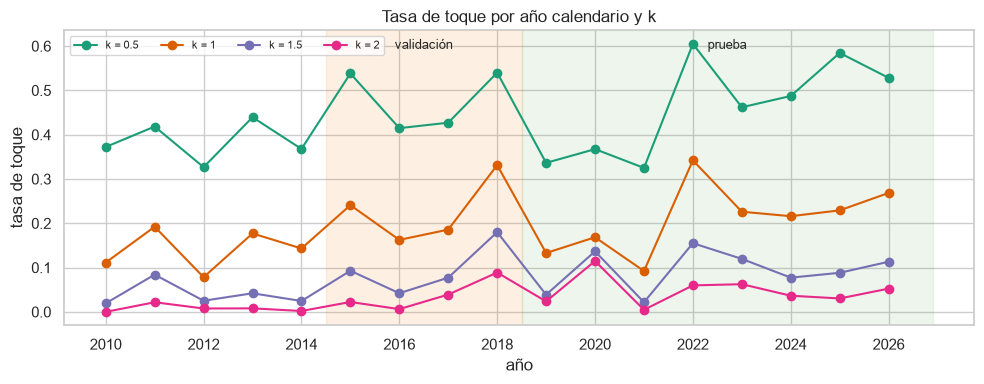

prueba por año (k = 1): {2019: 0.133, 2020: 0.168, 2021: 0.092, 2022: 0.342, 2023: 0.226, 2024: 0.216, 2025: 0.229, 2026: 0.268}


In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
for k, col in zip(cm.K_GRID, ["#1b9e77", "#d95f02", "#7570b3", "#e7298a"]):
    ax.plot(tasa_anio.index, tasa_anio[("mean", k)], marker="o", color=col, label=f"k = {k:g}")
ax.axvspan(2014.5, 2018.5, color="#f58518", alpha=0.12); ax.axvspan(2018.5, 2026.9, color="#54a24b", alpha=0.10)
ax.text(2016.5, ax.get_ylim()[1] * 0.97, "validación", ha="center", va="top", fontsize=9)
ax.text(2022.7, ax.get_ylim()[1] * 0.97, "prueba", ha="center", va="top", fontsize=9)
ax.set_xlabel("año"); ax.set_ylabel("tasa de toque"); ax.set_title("Tasa de toque por año calendario y k"); ax.set_xticks(range(2010, 2027, 2)); ax.legend(ncol=4, fontsize=8, loc="upper left")
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS_E2 / "nb06_tasa_por_anio.png", dpi=130); plt.show()
print("prueba por año (k = 1):", {int(a): round(float(tasa_anio.loc[a, ("mean", 1.0)]), 3) for a in tasa_anio.index if a >= 2019})

**Lectura.** La tasa de toque de la prueba no es estable (k = 1): 0,133 en 2019, 0,168 en 2020, 0,092 en 2021, 0,342 en 2022, 0,226, 0,216 y 0,229 en 2023–2025 y 0,268 en 2026 (hasta julio). Va de 0,092 (2021) a 0,342 (2022): una métrica global de 2019–2026 mezclaría un año de piso de 9 % con uno de 34 %, y por eso la prueba se reporta por año. Las cuatro curvas de k suben y bajan juntas, salvo 2020, cuando la caída del COVID eleva la tasa de k = 2 (0,115) casi al nivel de k = 1,5 (0,137): movimientos extremos y breves. En validación, 2015 (0,241 con k = 1) y 2018 (0,331) son los años que más pesan.

## 8. Resultados guardados

In [13]:
cm.DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
destino = cm.DIR_RESULTADOS / "nb06.json"
destino.write_text(json.dumps(res, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print(f"Escrito: {destino.name} — claves: {list(res)}")

Escrito: nb06.json — claves: ['particion', 'brecha', 'fin_prueba', 'fuga_etiquetas', 'fuga_etiquetas_detalle', 'conservacion', 'criterios_conservacion', 'ic_incluyen_cero', 'ic_dif_tasa_pp', 'tasa_por_anio', 'tasa_por_subperiodo', 'peso_subperiodo_en_conjunto']
